# K2 — Traçabilité et licences des générations

**Module GenAI 2026-2027 · difficulté 2/5**

Objectif : associer à chaque contenu généré (texte, image, audio) un **manifeste JSON** qui trace ses modèles, son prompt, ses sources, ses transformations et ses contraintes de licence, puis **vérifier automatiquement** ce manifeste.

Le verrou technique n'est pas de produire un texte juridique, mais une traçabilité **exploitable et vérifiable** :
1. un manifeste structuré et des empreintes SHA-256 ;
2. huit règles de compatibilité ;
3. une campagne d'évaluation avec des violations **injectées** dont on connaît la vérité terrain ;
4. une interface d'audit.

> Les règles de licence sont une modélisation pédagogique simplifiée des clauses Creative Commons et de quelques licences de modèles. Elles ne constituent pas un avis juridique.

In [1]:
from k2trace.licenses import LICENSES, ALIASES, norm
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", None)

df = pd.DataFrame([vars(l) for l in LICENSES.values()]).set_index("spdx")
print(df)
print()
print("Normalisation d'alias :", {a: norm(a) for a in ["CC BY 4.0", "MIT License", "CC-BY-4"]})

                          commercial  derivatives  share_alike  attribution     kind
spdx                                                                                
CC0-1.0                         True         True        False        False  content
CC-BY-4.0                       True         True        False         True  content
CC-BY-SA-4.0                    True         True         True         True  content
CC-BY-NC-4.0                   False         True        False         True  content
CC-BY-NC-SA-4.0                False         True         True         True  content
CC-BY-ND-4.0                    True        False        False         True  content
MIT                             True         True        False         True    model
Apache-2.0                      True         True        False         True    model
BSD-3-Clause                    True         True        False         True    model
OpenRAIL-M                      True         True        False   

## 1. Le manifeste

Champs obligatoires : version, identifiant, type de média, date, usage visé (commercial ou non), licence de sortie, empreinte du contenu, modèles, prompt (texte + empreinte), sources, transformations, attributions. Le champ `parents` relie un contenu dérivé à son contenu d'origine (chaîne de provenance).

In [2]:
from k2trace.pipelines import Factory
import json

f = Factory(seed=3)
texte = f.text_pipeline("commercial")
print(json.dumps(texte["manifest"], indent=2, ensure_ascii=False))

{
  "manifest_version": "1.0",
  "artifact_id": "text-0001",
  "media_type": "text",
  "created_at": "2026-10-01T00:01:00Z",
  "intended_use": "commercial",
  "output_license": "CC-BY-SA-4.0",
  "content_sha256": "72cb3444f57ac1420fcc8793ad0ee75bd885541103c10b0456d6086988d0f7b9",
  "models": [
    {
      "name": "TextGen-7B",
      "version": "1.2",
      "license": "Apache-2.0"
    }
  ],
  "prompt": {
    "text": "Rédige une synthèse de 200 mots sur le recyclage du cuir à partir des sources fournies.",
    "sha256": "f218b2cde53892d8ec01f10361a6c4c22d38c1a57f2e11802e4814b0c7e8419c"
  },
  "sources": [
    {
      "id": "src-0001",
      "title": "Article n°1",
      "author": "Auteur-0001",
      "license": "CC-BY-SA-4.0",
      "url": "https://example.org/article/1",
      "sha256": "2d6672ab91db1f581506d1a87e75dea94046a8e5cfa3e928fa077bc91df31ba9"
    },
    {
      "id": "src-0002",
      "title": "Article n°2",
      "author": "Auteur-0002",
      "license": "CC0-1.0",
      "ur

## 2. Trois pipelines média

- **Texte** : recherche de sources puis génération (RAG simulé).
- **Image** : génération à partir d'images de référence puis upscaling (deux modèles).
- **Audio** : narration TTS d'un texte existant + musique d'ambiance. Le manifeste audio **hérite des sources** du texte et pointe vers lui via `parents`.

Les contenus sont simulés de façon déterministe : le sujet porte sur la traçabilité, pas sur la qualité de génération (et le budget reste à 0 €).

In [3]:
from k2trace.manifest import manifest_hash
audio = f.audio_pipeline(texte)
m = audio["manifest"]
print("Parent déclaré      :", m["parents"][0][:16], "…")
print("Empreinte du texte  :", manifest_hash(texte["manifest"])[:16], "…")
print("Sources héritées    :", [s["id"] for s in m["sources"]])
print("Transformations     :", [t["step"] for t in m["transformations"]])

Parent déclaré      : f261fca6dfbcce3a …
Empreinte du texte  : f261fca6dfbcce3a …
Sources héritées    : ['src-0001', 'src-0002', 'src-0003']
Transformations     : ['tts', 'mix']


## 3. Les huit règles

| Règle | Ce qui est vérifié |
|---|---|
| R1 | Tous les champs obligatoires sont présents et non vides |
| R2 | Chaque licence est reconnue (après normalisation des alias) |
| R3 | Aucune source/modèle « non commercial » pour un usage commercial, et pas de licence de sortie plus permissive |
| R4 | Aucune source « ND » (pas de modification) dans une chaîne qui transforme |
| R5 | Une source « SA » impose la même licence en sortie |
| R6 | Chaque auteur dont la licence exige une attribution est crédité |
| R7 | L'empreinte du contenu et celle du prompt correspondent |
| R8 | Chaque parent existe dans le registre des manifestes |

In [4]:
from k2trace.rules import check
import copy

fautif = copy.deepcopy(texte)
fautif["manifest"]["sources"].append({"id": "src-X", "title": "Photo NC", "author": "Alice",
    "license": "CC BY-NC 4.0", "url": "https://example.org/x", "sha256": "0"*64})
fautif["content"] += b" retouche"

print("Manifeste original :", check(texte["manifest"], texte["content"]) or "conforme")
for c in check(fautif["manifest"], fautif["content"]):
    print(c["rule"], "→", c["message"])

Manifeste original : conforme
R3 → src-X (CC BY-NC 4.0) interdit l'usage commercial visé
R6 → src-X : l'auteur « Alice » n'est pas crédité
R7 → l'empreinte du contenu ne correspond pas au fichier


## 4. Campagne d'évaluation

Corpus construit avec la graine 42 :
- **150 manifestes conformes** (60 textes, 45 images, 45 audios), dont des cas « pièges » légaux : source NC pour un usage non commercial, source SA avec la bonne licence de sortie, alias de licences ;
- **120 violations simples** (15 par règle) et **20 doubles violations**, soit 140 manifestes fautifs.

Deux comparateurs :
- **baseline naïve** : liste noire par mots-clés (« NC », « ND », « SA »), comparaison exacte des licences, aucune vérification d'empreinte ;
- **vérificateur v2** : les huit règles.

In [5]:
from k2trace.evaluate import full_evaluation
res = full_evaluation(42)

synth = pd.DataFrame({"Baseline naïve": res["summary_naive"], "Vérificateur v1": res["summary_v1"],
                      "Vérificateur v2": res["summary_full"]})
print(synth.round(3))

                               Baseline naïve  Vérificateur v1  Vérificateur v2
n_total                               290.000            290.0            290.0
n_conformes                           150.000            150.0            150.0
n_violations                          140.000            140.0            140.0
fausses_alertes_sur_conformes         112.000              0.0              0.0
taux_fausses_alertes                    0.747              0.0              0.0
violations_detectees                   77.000            140.0            140.0
taux_detection                          0.550              1.0              1.0
diagnostic_exact                        0.231              1.0              1.0
micro_precision                         0.247              1.0              1.0
micro_recall                            0.594              1.0              1.0
micro_f1                                0.349              1.0              1.0


In [6]:
from k2trace.rules import RULES
rows = []
for r in RULES:
    a, b = res["metrics_naive"][r], res["metrics_full"][r]
    rows.append({"règle": r, "baseline P": None if a["tp"]+a["fp"]==0 else round(a["precision"],3),
                 "baseline R": round(a["recall"],3), "v2 P": round(b["precision"],3),
                 "v2 R": round(b["recall"],3), "TP": b["tp"], "FP": b["fp"], "FN": b["fn"]})
print(pd.DataFrame(rows).set_index("règle"))

       baseline P  baseline R  v2 P  v2 R  TP  FP  FN
règle                                                
R1          1.000         1.0   1.0   1.0  15   0   0
R2          0.188         1.0   1.0   1.0  15   0   0
R3          0.290         1.0   1.0   1.0  27   0   0
R4          1.000         1.0   1.0   1.0  23   0   0
R5          0.086         1.0   1.0   1.0  15   0   0
R6            NaN         0.0   1.0   1.0  25   0   0
R7            NaN         0.0   1.0   1.0  25   0   0
R8            NaN         0.0   1.0   1.0  15   0   0


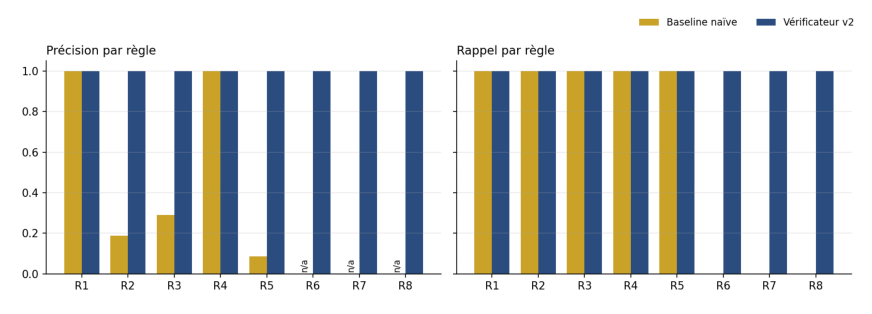

In [7]:
import matplotlib.pyplot as plt
import run_all
run_all.plot_rules(res, "outputs/precision_rappel.png")
from matplotlib import image as mpimg
fig, ax = plt.subplots(figsize=(11, 3.9)); ax.imshow(mpimg.imread("outputs/precision_rappel.png")); ax.axis("off")

**Lecture.** La baseline détecte les violations « visibles » dans le nom des licences (R3, R4, R5), mais au prix d'énormément de fausses alertes : elle signale toute licence SA ou NC même quand elle est utilisée légalement, et rejette les alias (« CC BY 4.0 »). Elle est aveugle aux violations qui demandent de croiser des champs (R6 attribution, R7 empreinte, R8 parent).

Le vérificateur obtient 100 % sur ce corpus. **Ce score est attendu et ne prouve pas grand-chose seul** : les violations ont été injectées par le même modèle que celui qui a servi à écrire les règles. D'où le test de robustesse ci-dessous.

## 5. Robustesse : métadonnées légales mais « sales »

Dans la vraie vie, les métadonnées sont saisies à la main : alias de licences fréquents (60 % ici), noms d'auteurs avec des casses et séparateurs différents (« AUTEUR-0012 », « auteur_0012 », « Auteur 0012 »). Ce corpus de 120 manifestes est **entièrement légal** : toute alerte est un faux positif.

                               n faux_positifs taux_faux_positifs                       par_regle
baseline naïve               120           115           0.958333  {'R2': 96, 'R5': 64, 'R3': 48}
vérificateur v1 (strict)     120           103           0.858333                     {'R6': 103}
vérificateur v2 (normalisé)  120             0                0.0                              {}


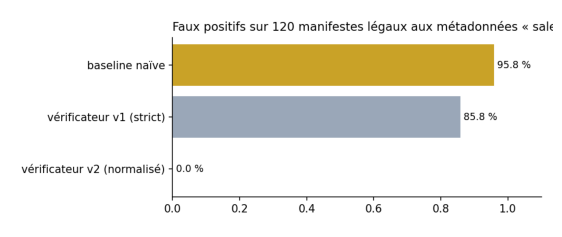

In [8]:
stress = pd.DataFrame(res["stress"]).T[["n", "faux_positifs", "taux_faux_positifs", "par_regle"]]
print(stress)
run_all.plot_stress(res["stress"], "outputs/robustesse.png")
fig, ax = plt.subplots(figsize=(7, 2.9)); ax.imshow(mpimg.imread("outputs/robustesse.png")); ax.axis("off")

**Analyse d'erreur.** La première version du vérificateur (v1) comparait les noms d'auteurs à l'identique : 86 % de faux positifs, tous sur R6. La correction (v2) normalise les noms (casse, espaces, tirets, underscores) avant comparaison : 0 faux positif, sans perte de détection sur le corpus principal (v1 et v2 ont le même score sur les 140 violations).

Limite assumée : la normalisation peut confondre deux auteurs dont les noms ne diffèrent que par la ponctuation. Un identifiant stable (ORCID, URI d'auteur) serait plus sûr.

## 6. Couverture des métadonnées et reproductibilité

In [9]:
from k2trace.evaluate import reproducibility
print("Couverture :", {k: round(v, 3) for k, v in res["coverage"].items()})
rep = reproducibility(42)
print("Export identique sur deux exécutions :", rep["identiques"])
print("Empreinte de l'export :", rep["hash_run_1"])
print("Une autre graine donne un export différent :", rep["graine_differente_differe"])

Couverture : {'moyenne_corpus': 0.998, 'moyenne_conformes': 1.0, 'minimum': 0.944}
Export identique sur deux exécutions : True
Empreinte de l'export : ba08ace25149344cafb975eefecef58f33836dd1ff6cf6b1d88cbc13b1419f8d
Une autre graine donne un export différent : True


## 7. Interface d'audit

`python run_all.py` écrit `outputs/audit.html` : une page autonome (ouvrable hors ligne) qui liste les 290 générations, filtre par statut, règle et média, et affiche pour chaque ligne les constats et le manifeste complet.

In [10]:
from k2trace.audit_ui import build_audit_html
html = build_audit_html(res["items"], res["rows_full"], res["summary_full"])
open("outputs/audit.html", "w", encoding="utf-8").write(html)
print(f"outputs/audit.html écrit ({len(html)//1024} Ko)")

outputs/audit.html écrit (420 Ko)


## 8. Correction de la validation de structure
Un prompt sans empreinte et des types incorrects déclenchent désormais R1. Les règles métier attendent une structure exploitable.
20 tests unitaires réussis après correction. Assistance Claude et ChatGPT déclarée.


In [11]:
"""Démonstration des corrections de structure. Assistance de ChatGPT déclarée."""
import copy
from k2trace.pipelines import Factory
from k2trace.rules import check

item = Factory(1).text_pipeline("commercial")
for name, change in [
    ("Manifeste correct", lambda m: None),
    ("Empreinte du prompt absente", lambda m: m["prompt"].pop("sha256")),
    ("Sources mal formatées", lambda m: m.update(sources=123)),
]:
    manifest = copy.deepcopy(item["manifest"])
    change(manifest)
    findings = check(manifest, item["content"], set())
    print(f"\n{name}")
    if not findings:
        print("Conforme aux règles du démonstrateur")
    for finding in findings:
        print(f"{finding['rule']} : {finding['message']}")



Manifeste correct
Conforme aux règles du démonstrateur

Empreinte du prompt absente
R1 : prompt.sha256 doit être une empreinte SHA-256 de 64 caractères hexadécimaux

Sources mal formatées
R1 : sources doit être une liste


## 8. Limites et extensions

- **Licences simplifiées** : quatre attributs par licence. Les clauses d'usage de type OpenRAIL (usages interdits) ne sont pas modélisées.
- **Corpus synthétique** : la vérité terrain est garantie, mais la diversité des erreurs réelles est sous-estimée ; le test de robustesse en montre une partie.
- **Confiance dans le manifeste** : une empreinte prouve qu'un contenu n'a pas changé depuis l'écriture du manifeste, pas que le manifeste dit la vérité. Une signature (extension C2PA) attacherait le manifeste à son émetteur.
- Extensions prévues par la fiche : manifeste C2PA signé, SBOM de modèles, politiques organisationnelles (ex. « aucun modèle research-only en production »).